In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

with open("Faults27x7_var") as f:
    cols = [l.strip() for l in f if l.strip()]
df = pd.read_csv("Faults.NNA", sep=r"\s+", header=None, names=cols)

feature_cols = df.columns[:27].tolist()
target_cols  = df.columns[27:].tolist()

In [2]:
print("shape:", df.shape)
print("정답 열 값 종류:", sorted(pd.unique(df[target_cols].values.ravel())))
print("행별 정답 합:", df[target_cols].sum(axis=1).value_counts().to_dict())

df["fault_type"] = df[target_cols].idxmax(axis=1)
X = df[feature_cols]
y = df["fault_type"]
print("X:", X.shape, "/ y:", y.shape)
print("정답 열이 X에 포함됐는가?", any(c in X.columns for c in target_cols))   # False여야 함

df.info()

shape: (1941, 34)
정답 열 값 종류: [np.int64(0), np.int64(1)]
행별 정답 합: {1: 1941}
X: (1941, 27) / y: (1941,)
정답 열이 X에 포함됐는가? False
<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 35 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  


               건수  비율(%)
fault_type              
Other_Faults  673  34.67
Bumps         402  20.71
K_Scatch      391  20.14
Z_Scratch     190   9.79
Pastry        158   8.14
Stains         72   3.71
Dirtiness      55   2.83
최대/최소 비율: 12.24


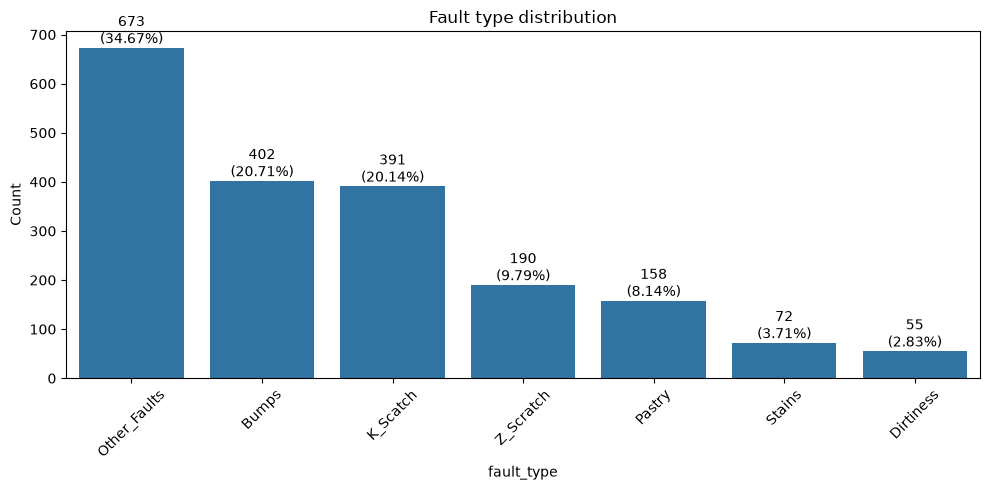

In [9]:
dist = pd.DataFrame({"건수": y.value_counts(),
                     "비율(%)": (y.value_counts(normalize=True) * 100).round(2)})
print(dist)
print("최대/최소 비율:", round(dist["건수"].max() / dist["건수"].min(), 2))

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=dist.index, y=dist["건수"])
for i, (n, r) in enumerate(zip(dist["건수"], dist["비율(%)"])):
    ax.text(i, n, f"{n}\n({r}%)", ha="center", va="bottom")
plt.xticks(rotation=45)
plt.title("Fault type distribution")
plt.ylabel("Count")      
plt.tight_layout(); plt.savefig("fig1_class_dist.png", dpi=150); plt.show()

,dtype,결측,고유값 수,최소,최대,IQR 이상치 수,이상치 비율(%),왜도
Sum_of_Luminosity,int64,0,1909,250.0000,1.159141e+07,399,20.6,7.73
Pixels_Areas,int64,0,920,2.0000,1.526550e+05,395,20.4,14.08
Outside_X_Index,float64,0,454,0.0015,8.759000e-01,370,19.1,5.18
X_Perimeter,int64,0,399,2.0000,1.044900e+04,352,18.1,21.54
Steel_Plate_Thickness,int64,0,24,40.0000,3.000000e+02,240,12.4,2.21
Y_Perimeter,int64,0,317,1.0000,1.815200e+04,179,9.2,39.29
Maximum_of_Luminosity,int64,0,100,37.0000,2.530000e+02,146,7.5,1.29
Luminosity_Index,float64,0,1522,-0.9989,6.421000e-01,134,6.9,0.68
Y_Minimum,int64,0,1939,6712.0000,1.298766e+07,81,4.2,2.81
Y_Maximum,int64,0,1940,6724.0000,1.298769e+07,81,4.2,2.81


중복 행: 0 / 입력값 기준 중복: 0
상수 컬럼: []
X_Max<X_Min: 0 / Y_Max<Y_Min: 0 / Min_Lum>Max_Lum: 0


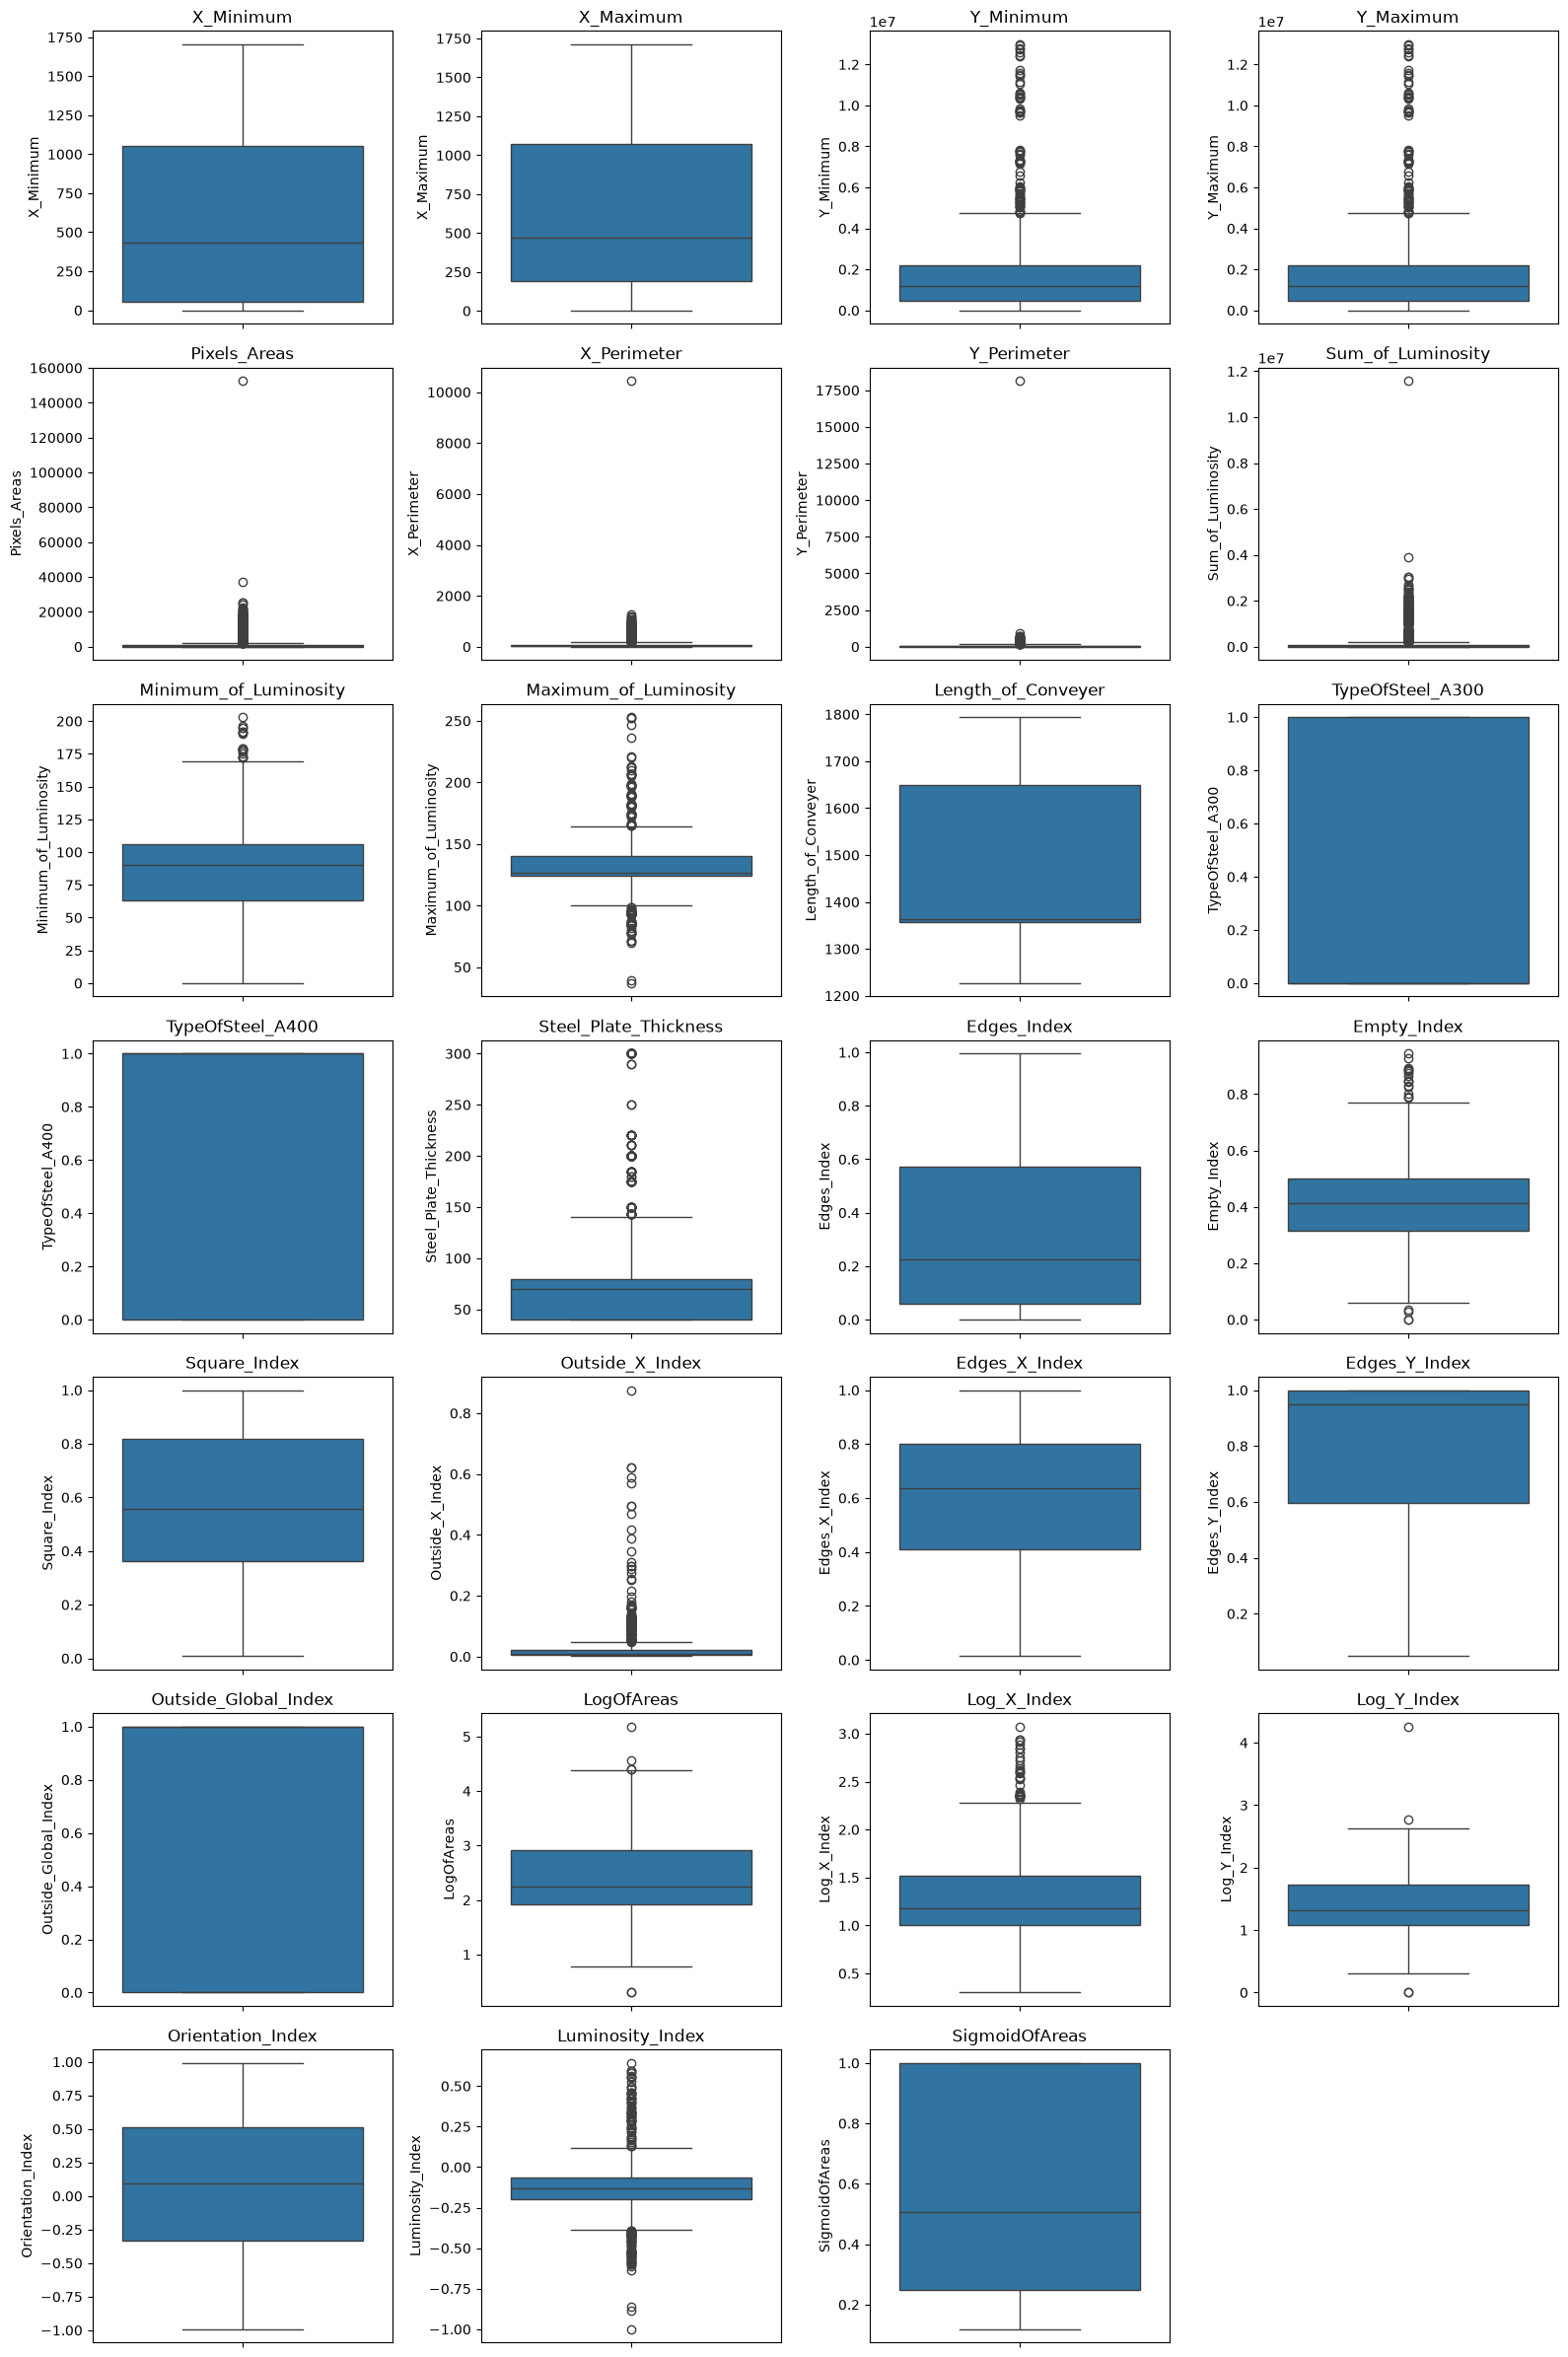

In [4]:
quality = pd.DataFrame({"dtype": X.dtypes.astype(str), "결측": X.isnull().sum(),
                        "고유값 수": X.nunique(), "최소": X.min(), "최대": X.max()})
q1, q3 = X.quantile(0.25), X.quantile(0.75); iqr = q3 - q1
n_out = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
quality["IQR 이상치 수"] = n_out
quality["이상치 비율(%)"] = (n_out / len(X) * 100).round(1)
quality["왜도"] = X.skew().round(2)
display(quality.sort_values("이상치 비율(%)", ascending=False))

print("중복 행:", df.duplicated().sum(), "/ 입력값 기준 중복:", X.duplicated().sum())
print("상수 컬럼:", [c for c in X if X[c].nunique() <= 1])

# 논리 검증
print("X_Max<X_Min:", (X.X_Maximum < X.X_Minimum).sum(),
      "/ Y_Max<Y_Min:", (X.Y_Maximum < X.Y_Minimum).sum(),
      "/ Min_Lum>Max_Lum:", (X.Minimum_of_Luminosity > X.Maximum_of_Luminosity).sum())

# 변수별 박스플롯 (이미 있는 셀 재사용 가능)
fig, axes = plt.subplots(7, 4, figsize=(16, 24)); axes = axes.flatten()
for i, c in enumerate(X.columns):
    sns.boxplot(y=X[c], ax=axes[i]); axes[i].set_title(c)
for j in range(len(X.columns), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout(); plt.savefig("fig2_boxplots.png", dpi=120); plt.show()

,Pixels_Areas,Steel_Plate_Thickness,Edges_Index,Outside_X_Index,Luminosity_Index,Orientation_Index
fault_type,,,,,,
Bumps,120.5,70.0,0.44,0.01,-0.14,0.10
Dirtiness,145.0,100.0,0.90,0.01,-0.09,0.80
K_Scatch,6281.0,40.0,0.06,0.11,-0.16,-0.52
Other_Faults,146.0,70.0,0.32,0.01,-0.12,0.18
Pastry,209.0,85.0,0.15,0.01,-0.18,0.67
Stains,16.5,50.0,0.59,0.00,-0.00,-0.27
Z_Scratch,146.0,70.0,0.15,0.01,-0.16,0.35


fault_type
Bumps           0.69
Dirtiness       0.16
K_Scatch        0.00
Other_Faults    0.40
Pastry          0.31
Stains          0.01
Z_Scratch       0.91
Name: TypeOfSteel_A300, dtype: float64


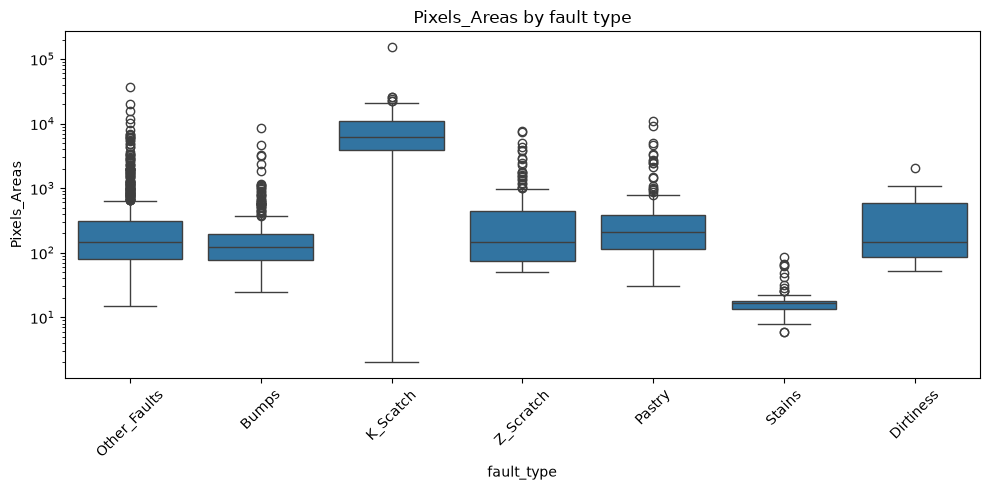

Log_X_Index          446.0
LogOfAreas           416.0
Edges_Y_Index        233.0
Outside_X_Index      219.0
Sum_of_Luminosity    199.0
Log_Y_Index          175.0
TypeOfSteel_A300     169.0
TypeOfSteel_A400     169.0
Pixels_Areas         145.0
SigmoidOfAreas       137.0
dtype: float64


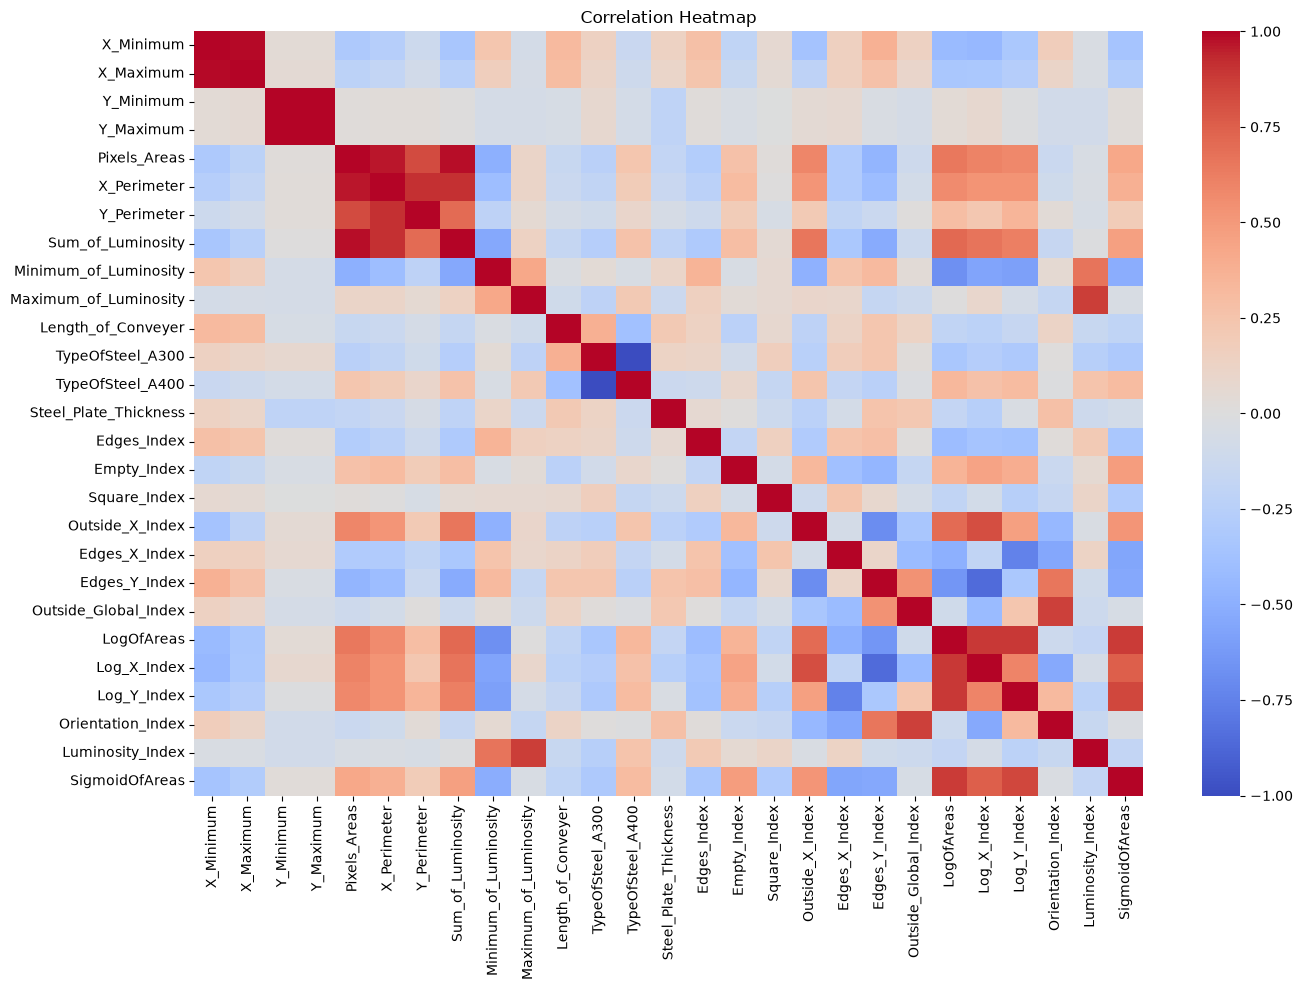

[('Y_Minimum', 'Y_Maximum', np.float64(1.0)), ('TypeOfSteel_A300', 'TypeOfSteel_A400', np.float64(1.0)), ('X_Minimum', 'X_Maximum', np.float64(0.988)), ('Pixels_Areas', 'Sum_of_Luminosity', np.float64(0.979)), ('Pixels_Areas', 'X_Perimeter', np.float64(0.967)), ('X_Perimeter', 'Sum_of_Luminosity', np.float64(0.913)), ('X_Perimeter', 'Y_Perimeter', np.float64(0.912))]


In [5]:
# 유형별 주요 변수 중앙값
key_cols = ["Pixels_Areas", "Steel_Plate_Thickness", "Edges_Index",
            "Outside_X_Index", "Luminosity_Index", "Orientation_Index"]
display(df.groupby("fault_type")[key_cols].median().round(2))
print(df.groupby("fault_type")["TypeOfSteel_A300"].mean().round(2))

# 유형별 면적 박스플롯 (로그 스케일)
plt.figure(figsize=(10, 5))
sns.boxplot(x=y, y=X["Pixels_Areas"], order=dist.index)
plt.yscale("log"); plt.xticks(rotation=45); plt.title("Pixels_Areas by fault type")
plt.tight_layout(); plt.savefig("fig3_area_by_type.png", dpi=150); plt.show()

# 변수-유형 관계 (ANOVA F, 클수록 유형 구분에 유리)
from sklearn.feature_selection import f_classif
F, _ = f_classif(X, y)
print(pd.Series(F, index=X.columns).sort_values(ascending=False).round(0).head(10))

# 상관 히트맵 + 0.9 이상 쌍
plt.figure(figsize=(14, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.tight_layout()
plt.savefig("fig4_corr.png", dpi=150); plt.show()

corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print(sorted([(r, c, round(upper.loc[r, c], 3)) for c in upper.columns for r in upper.index
              if upper.loc[r, c] >= 0.9], key=lambda t: -t[2]))

In [6]:
df["steel_type"] = df["TypeOfSteel_A300"].map({1: "A300", 0: "A400"})

# 강종별 건수
print(df["steel_type"].value_counts())

# 강종 × 결함 유형 건수
print(pd.crosstab(df["steel_type"], df["fault_type"]))

# 강종별 유형 구성 비율 (각 행의 합이 100%)
print((pd.crosstab(df["steel_type"], df["fault_type"], normalize="index") * 100).round(1))

steel_type
A400    1164
A300     777
Name: count, dtype: int64
fault_type  Bumps  Dirtiness  K_Scatch  Other_Faults  Pastry  Stains  \
steel_type                                                             
A300          279          9         1           266      49       1   
A400          123         46       390           407     109      71   

fault_type  Z_Scratch  
steel_type             
A300              172  
A400               18  
fault_type  Bumps  Dirtiness  K_Scatch  Other_Faults  Pastry  Stains  \
steel_type                                                             
A300         35.9        1.2       0.1          34.2     6.3     0.1   
A400         10.6        4.0      33.5          35.0     9.4     6.1   

fault_type  Z_Scratch  
steel_type             
A300             22.1  
A400              1.5  


In [7]:
from sklearn.feature_selection import f_classif
F, _ = f_classif(X, y)
print(pd.Series(F, index=X.columns).sort_values(ascending=False).round(0))

Log_X_Index              446.0
LogOfAreas               416.0
Edges_Y_Index            233.0
Outside_X_Index          219.0
Sum_of_Luminosity        199.0
Log_Y_Index              175.0
TypeOfSteel_A300         169.0
TypeOfSteel_A400         169.0
Pixels_Areas             145.0
SigmoidOfAreas           137.0
Orientation_Index        125.0
X_Minimum                123.0
Minimum_of_Luminosity    111.0
X_Maximum                 92.0
Length_of_Conveyer        86.0
X_Perimeter               85.0
Edges_Index               80.0
Steel_Plate_Thickness     71.0
Square_Index              66.0
Outside_Global_Index      65.0
Edges_X_Index             60.0
Empty_Index               32.0
Maximum_of_Luminosity     26.0
Luminosity_Index          22.0
Y_Perimeter               14.0
Y_Minimum                 10.0
Y_Maximum                 10.0
dtype: float64
